# 2.6 — Resumen del procesamiento

Las libretas `2.0` a `2.5` convierten cada fuente en una **tabla tidy de
Hermosillo**: una fila por mes (o por semana epidemiológica), lista para
unirse con las demás en el panel.

| Capa | Libreta | De → a | Decisión principal |
|------|---------|--------|--------------------|
| Temperatura SMN | `2.0` | estación × mes → mes | Promedio de las estaciones de Hermosillo; 3 diciembres dañados → vacíos |
| Calor (Open-Meteo) | `2.1` | día → mes y semana | Ola de calor = 3+ días con máxima y mínima sobre su percentil 95 del mes |
| Sequía | `2.2` | quincena → mes y semana | Severidad promedio + categoría más frecuente |
| Marginación | `2.3` | censo (2015, 2020) → mes | Interpolación lineal entre censos |
| Calidad del aire | `2.4` | hora → día → semana y mes | Limpieza por banderas; solo se interpolan huecos cortos |
| Salud (IRA) | `2.5` | registro → semana y mes | Suma de casos de Hermosillo; casos por semana para comparar meses |

**Cómo leer las gráficas:** en todas, **gris = antes** del procesamiento y
**azul = después**.

In [1]:
from pathlib import Path
import sys

sys.path.append(str(Path.cwd().parent.parent))  # raíz del proyecto

import matplotlib.pyplot as plt
import pandas as pd

from sonora_health_climate_eda import panel  # funciones que hacen el procesamiento
from sonora_health_climate_eda.config import CLIMATE_STATION_IDS, FIGURES_DIR, PROCESSED_DATA_DIR

P = PROCESSED_DATA_DIR
GRIS, AZUL = "#9aa4b1", "#2a78d6"  # antes / después
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})

## 1. Temperatura SMN (`2.0`)

- Se toman las 3 estaciones del SMN en Hermosillo y se **promedian** por mes.
- Diciembre de 2015, 2016 y 2017 traen el mismo valor en media, máxima y
  mínima (archivo dañado de la fuente) → se dejan **vacíos**.

In [2]:
clima = pd.read_parquet(P / "climate_hermosillo.parquet")
print(f"{len(clima)} meses | meses vacíos: {clima.loc[clima['temp_media_c'].isna(), 'fecha_mes'].dt.strftime('%Y-%m').tolist()}")
clima.drop(columns="fecha_mes").describe().loc[["min", "mean", "max"]].round(1)

72 meses | meses vacíos: ['2015-12', '2016-12', '2017-12']


,temp_media_c,temp_max_media_c,temp_min_media_c
min,17.0,24.6,8.2
mean,26.5,34.4,18.7
max,35.2,42.3,28.0


2026-11-17 17:09:38.750 | INFO     | sonora_health_climate_eda.panel:_load_smn_temperature_series:96 - SMN temp_media_c: 77027 filas estación-mes.


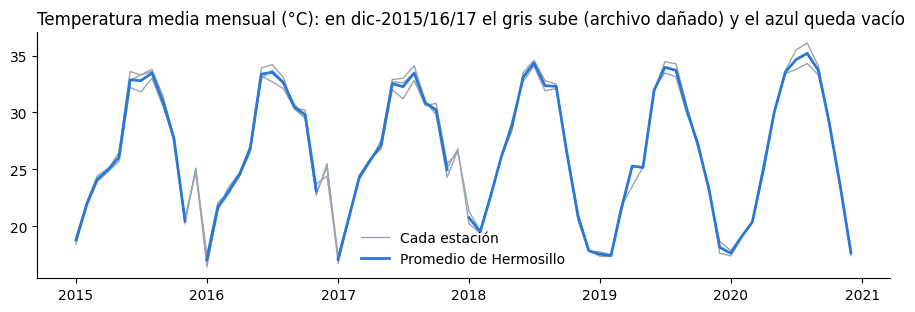

In [3]:
# Antes: cada estación por separado. Después: el promedio mensual de Hermosillo.
estaciones = panel.load_smn_temperature().query("clave in @CLIMATE_STATION_IDS")

fig, ax = plt.subplots(figsize=(11, 3.2))
for i, (clave, df) in enumerate(estaciones.groupby("clave")):
    ax.plot(df["fecha_mes"].dt.to_timestamp(), df["temp_media_c"], color=GRIS, lw=1,
            label="Cada estación" if i == 0 else None)
ax.plot(clima["fecha_mes"], clima["temp_media_c"], color=AZUL, lw=2, label="Promedio de Hermosillo")
ax.set_title("Temperatura media mensual (°C): en dic-2015/16/17 el gris sube (archivo dañado) y el azul queda vacío", loc="left")
ax.legend(frameon=False)
plt.show()

## 2. Calor extremo con Open-Meteo (`2.1`)

- Con los datos **diarios** se cuentan días ≥ 35 °C y **olas de calor**.
- Ola de calor = 3 o más días seguidos en que la máxima **y** la mínima
  superan el **percentil 95** de ese mes (calculado con 1991–2020). Es la
  métrica principal porque la regla fija de 35 °C marca casi todo el
  verano.
- El índice de calor (temperatura + humedad) **exagera** los valores: solo
  sirve para comparar días entre sí.

In [4]:
calor = pd.read_parquet(P / "openmeteo_hermosillo_monthly.parquet")
print(f"{len(calor)} meses")
print(f"Días con máxima ≥ 35 °C (2015–2020): {calor['dias_tmax_ge_35'].sum()}")
print(f"Olas con la regla fija de 35 °C:     {calor['n_olas_calor'].sum()}")
print(f"Olas con el percentil 95:             {calor['n_olas_calor_p95'].sum()}")

72 meses
Días con máxima ≥ 35 °C (2015–2020): 810
Olas con la regla fija de 35 °C:     69
Olas con el percentil 95:             5


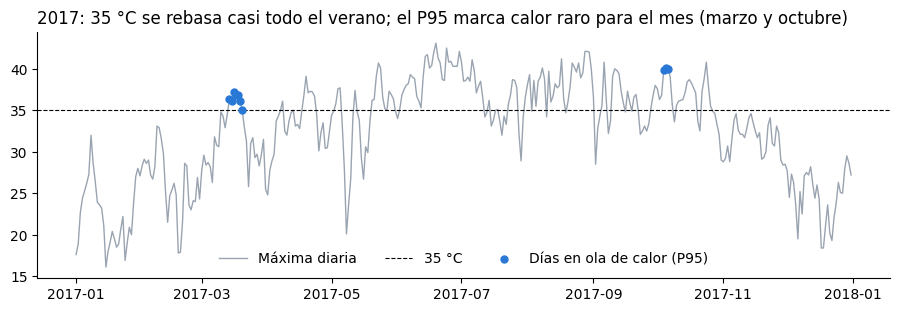

In [5]:
# Un año de ejemplo: la máxima diaria y los días que quedaron dentro de una ola P95
diario = panel._openmeteo_daily_flags()
anio = diario[diario["fecha"].dt.year == 2017]
ola = anio[anio["en_ola_p95"] == 1]

fig, ax = plt.subplots(figsize=(11, 3.2))
ax.plot(anio["fecha"], anio["tmax_c"], color=GRIS, lw=1, label="Máxima diaria")
ax.axhline(35, color="black", ls="--", lw=0.8, label="35 °C")
ax.scatter(ola["fecha"], ola["tmax_c"], color=AZUL, s=25, zorder=3, label="Días en ola de calor (P95)")
ax.set_title("2017: 35 °C se rebasa casi todo el verano; el P95 marca calor raro para el mes (marzo y octubre)", loc="left")
ax.legend(frameon=False, loc="lower center", ncol=3)
plt.show()

## 3. Sequía (`2.2`)

- El monitor es **quincenal**: cada mes junta dos registros.
- Por mes se guarda la **severidad promedio** (0 = sin sequía, 5 =
  excepcional) y la **categoría más frecuente**.

In [6]:
sequia = pd.read_parquet(P / "drought_hermosillo.parquet")
print(f"{len(sequia)} meses")
sequia["categoria_sequia"].value_counts().rename("meses")

72 meses


categoria_sequia
Normal    31
D0        21
D1         9
D2         7
D3         4
Name: meses, dtype: int64

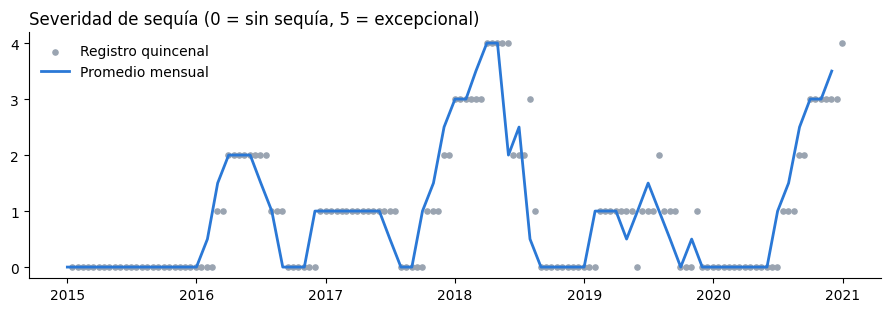

In [7]:
# Antes: dos registros por mes (quincenal). Después: la severidad promedio del mes.
quincenal = panel._drought_records_hermosillo()

fig, ax = plt.subplots(figsize=(11, 3.2))
ax.scatter(quincenal["fecha"], quincenal["severidad_num"], color=GRIS, s=14, label="Registro quincenal")
ax.plot(sequia["fecha_mes"], sequia["severidad_sequia"], color=AZUL, lw=2, label="Promedio mensual")
ax.set_title("Severidad de sequía (0 = sin sequía, 5 = excepcional)", loc="left")
ax.legend(frameon=False)
plt.show()

## 4. Marginación (`2.3`)

- Solo hay datos de los censos **2015 y 2020**; los meses intermedios se
  **interpolan en línea recta**.
- Se usa el índice `IM`. El índice normalizado `IMN` se descarta porque
  cada año usa una escala distinta y no se puede comparar.
- **Ojo al leerlo:** con el método de CONAPO, un `IM` **más alto** significa
  **menos** marginación. Hermosillo sube de 51.5 a 60.4: mejoró.

In [8]:
marginacion = pd.read_parquet(P / "marginacion_hermosillo.parquet")
print(f"{len(marginacion)} meses | IM: {marginacion['IM'].iloc[0]:.1f} (ene-2015) → {marginacion['IM'].iloc[-1]:.1f} (dic-2020)")

72 meses | IM: 51.5 (ene-2015) → 60.4 (dic-2020)


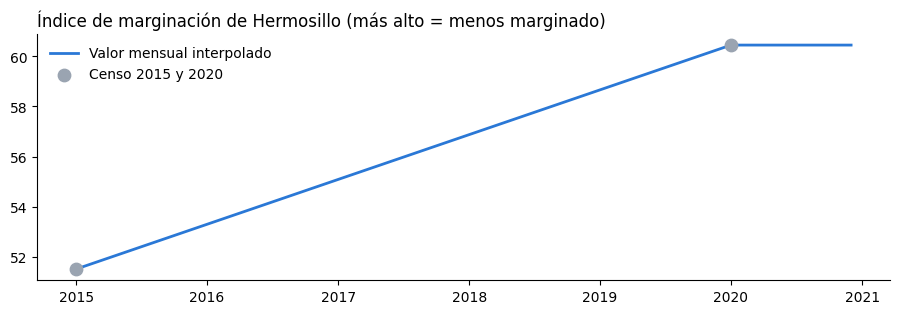

In [9]:
# Antes: solo dos valores (censos). Después: un valor por mes, en línea recta entre ellos.
censos = marginacion[marginacion["fecha_mes"].isin(pd.to_datetime(["2015-01-01", "2020-01-01"]))]

fig, ax = plt.subplots(figsize=(11, 3.2))
ax.plot(marginacion["fecha_mes"], marginacion["IM"], color=AZUL, lw=2, label="Valor mensual interpolado")
ax.scatter(censos["fecha_mes"], censos["IM"], color=GRIS, s=80, zorder=3, label="Censo 2015 y 2020")
ax.set_title("Índice de marginación de Hermosillo (más alto = menos marginado)", loc="left")
ax.legend(frameon=False)
plt.show()

## 5. Calidad del aire (`2.4`)

Es la capa con más pasos:

1. **Limpieza horaria:** valores fuera de rango o con el equipo fuera de
   servicio → vacíos; valores debajo del límite de detección → la mitad de
   ese límite; picos imposibles de ozono → vacíos.
2. **Hora → día:** un día cuenta solo si tiene al menos 18 horas válidas
   (75 %, criterio de las NOM).
3. **Día → semana y mes:** promedio de los días válidos; cada periodo
   guarda también su **peor día** según el Índice AIRE Y SALUD.
4. **Huecos:** solo se rellenan los **cortos** (≤ 2 semanas o 1 mes) y
   quedan marcados; los largos se dejan vacíos.

Limitaciones: **PM2.5 no tiene datos desde junio de 2018** (se usa PM10
como indicador de partículas) y **de junio a noviembre de 2018 no hay
ningún contaminante**.

In [10]:
horario = pd.read_csv(PROCESSED_DATA_DIR.parent / "interim" / "aire" / "aire_hermosillo_horario.csv")
diario_aire = pd.read_csv(PROCESSED_DATA_DIR.parent / "interim" / "aire" / "aire_hermosillo_diario.csv")
aire = pd.read_csv(P / "aire" / "aire_hermosillo_mensual.csv")
print(f"{len(horario):,} horas → {len(diario_aire):,} días → {len(aire)} meses")

pd.DataFrame({
    "meses con dato (de 72)": [aire[c].notna().sum() for c in ["pm25_ugm3", "pm10_ugm3", "o3_max8h_ppb"]],
}, index=["PM2.5", "PM10", "Ozono"])

52,608 horas → 2,192 días → 72 meses


,meses con dato (de 72)
PM2.5,38
PM10,64
Ozono,61


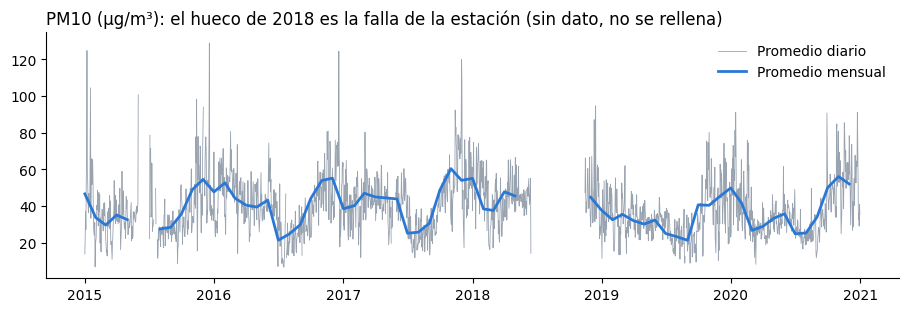

In [11]:
# Antes: el promedio de cada día. Después: el promedio de cada mes.
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.plot(pd.to_datetime(diario_aire["fecha"]), diario_aire["pm10_ugm3"], color=GRIS, lw=0.6, label="Promedio diario")
ax.plot(pd.to_datetime(aire["fecha_mes"]), aire["pm10_ugm3"], color=AZUL, lw=2, label="Promedio mensual")
ax.set_title("PM10 (µg/m³): el hueco de 2018 es la falla de la estación (sin dato, no se rellena)", loc="left")
ax.legend(frameon=False)
plt.show()

## 6. Salud: infecciones respiratorias (`2.5`)

- Se filtra a **Hermosillo** y a 2015–2020, y se **suman** los casos de
  todas las unidades, edades y sexos por semana epidemiológica.
- Un mes puede tener **4 o 5 semanas**, así que se agrega
  `casos_ira_por_semana` para comparar meses de forma justa.
- **2020 se marca como año atípico** (COVID cambió cómo se buscaba atención).

In [12]:
salud = pd.read_parquet(P / "health_ira_monthly.parquet")
print(f"{len(salud)} meses | {salud['casos_ira'].sum():,} casos en 2015–2020")
print(f"Meses con 4 semanas: {(salud['n_semanas'] == 4).sum()} | con 5 semanas: {(salud['n_semanas'] == 5).sum()}")
salud.groupby(salud["fecha_mes"].dt.year)["casos_ira"].sum().rename("casos por año")

72 meses | 1,129,099 casos en 2015–2020
Meses con 4 semanas: 47 | con 5 semanas: 25


fecha_mes
2015    187360
2016    189480
2017    209362
2018    229643
2019    199842
2020    113412
Name: casos por año, dtype: int64

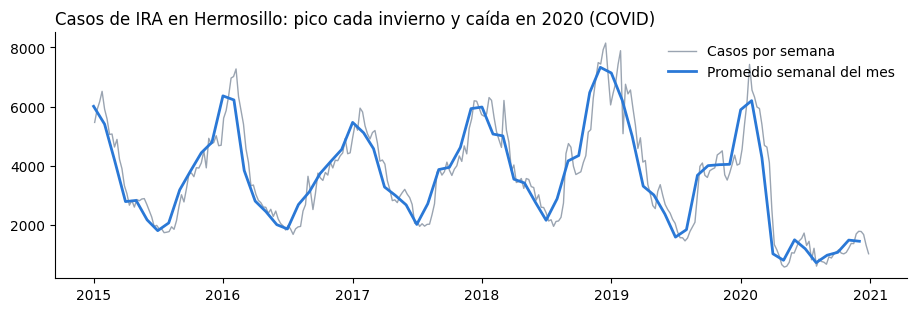

In [13]:
# Antes: el total de cada semana. Después: el promedio semanal de cada mes.
semanal = pd.read_parquet(P / "health_ira_weekly.parquet")

fig, ax = plt.subplots(figsize=(11, 3.2))
ax.plot(semanal["fecha_semana"], semanal["casos_ira_total"], color=GRIS, lw=1, label="Casos por semana")
ax.plot(salud["fecha_mes"], salud["casos_ira_por_semana"], color=AZUL, lw=2, label="Promedio semanal del mes")
ax.set_title("Casos de IRA en Hermosillo: pico cada invierno y caída en 2020 (COVID)", loc="left")
ax.legend(frameon=False)
plt.show()

## Resultado: una serie mensual por capa

Las seis tablas tienen los mismos 72 meses, así que se pueden poner lado a
lado (eso hace el panel, en `3.0`). Los huecos en las líneas son los meses
vacíos explicados arriba.

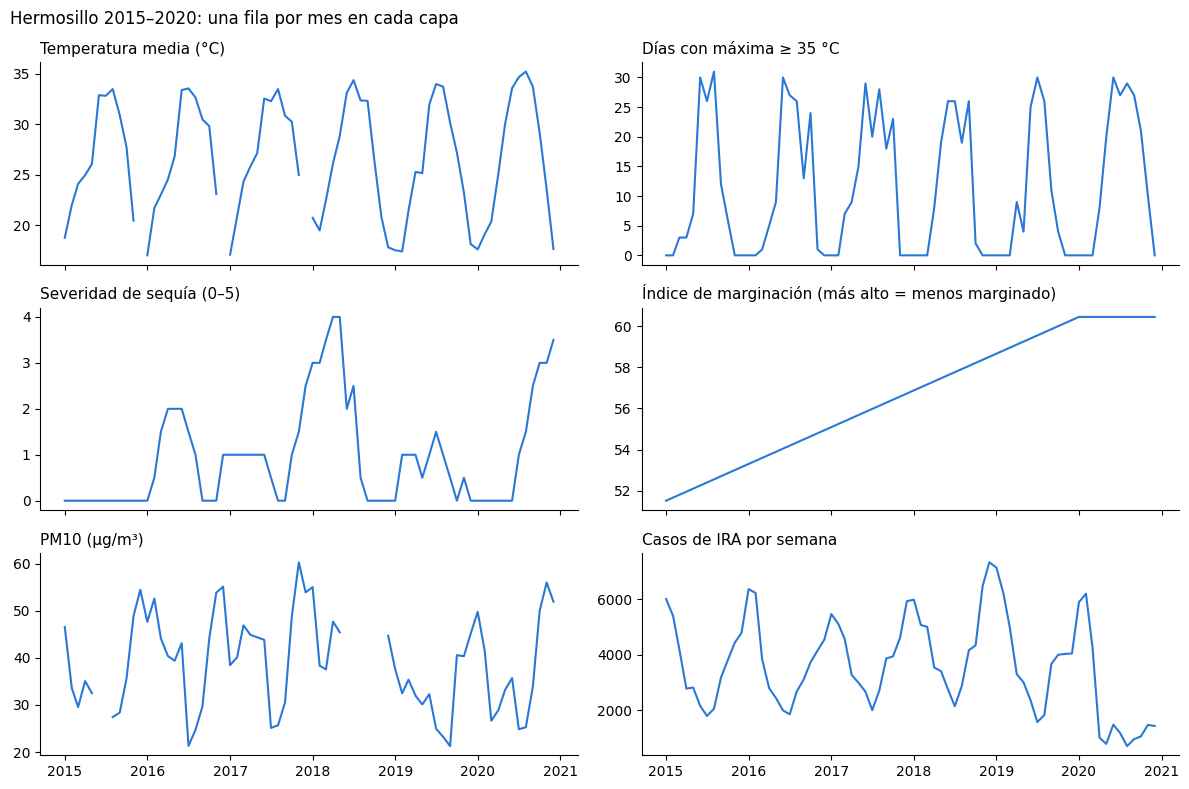

In [14]:
series = [
    (clima, "temp_media_c", "Temperatura media (°C)"),
    (calor, "dias_tmax_ge_35", "Días con máxima ≥ 35 °C"),
    (sequia, "severidad_sequia", "Severidad de sequía (0–5)"),
    (marginacion, "IM", "Índice de marginación (más alto = menos marginado)"),
    (aire, "pm10_ugm3", "PM10 (µg/m³)"),
    (salud, "casos_ira_por_semana", "Casos de IRA por semana"),
]

fig, axes = plt.subplots(3, 2, figsize=(12, 8), sharex=True)
for ax, (df, columna, titulo) in zip(axes.flat, series):
    ax.plot(pd.to_datetime(df["fecha_mes"]), df[columna], color="#2a78d6", lw=1.5)
    ax.set_title(titulo, loc="left", fontsize=11)
fig.suptitle("Hermosillo 2015–2020: una fila por mes en cada capa", x=0.01, ha="left")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "procesamiento_series_mensuales.png", dpi=150, bbox_inches="tight")
plt.show()

## En resumen

- Cada fuente quedó como una **tabla de Hermosillo con 72 meses** (y 313
  semanas donde aplica), lista para el panel.
- Los cambios a los datos son pocos y están justificados: **promediar**,
  **sumar**, **interpolar solo lo razonable** y **dejar vacío lo que no se
  puede reconstruir**.
- Limitaciones a recordar: marginación interpolada, una sola estación de
  aire sin PM2.5 desde 2018 y 2020 atípico por COVID.